### From graph to efficiency

1. Star topology graph (cavity + N identical emitters)
2. Adjecency matrix, energy landscape, and Hamiltonian
3. Incoherent transition and anti-Hermitian term
4. Full effective non-Hermitian Hamiltonian and spectrum
5. Efficieny of electron transfer channel

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.linalg import eig, expm

### Useful functions

In [2]:
def bright_states(H, dips, tol=1e-8, d0=1.0):
    # eigenstates of the Hermitian H (columns of C) and their transition dipoles D_k = sum_m c_m^(k) d_m
    E, C = np.linalg.eigh(H)
    i = 0
    while i < len(E):                                                   # find blocks of equal energy
        j = i + 1
        while j < len(E) and E[j] - E[i] < tol:
            j += 1
        if j - i > 1:                                                   # rotate the block: at most 3 bright states
            _, _, Vh = np.linalg.svd(dips.T @ C[:, i:j])
            C[:, i:j] = C[:, i:j] @ Vh.conj().T
        i = j
    D = C.T @ dips                                                      # row k is D_k
    B = np.sum(np.abs(D) ** 2, axis=1) / d0 ** 2                        # brightness B_k = |D_k|^2 / d0^2
    return E, C, D, B

def star(dipoles, energies, g, field_c, d0=1.0):
    # H = D + A with the cavity as node 0; dipole array with a zero row for the cavity
    gm = g * dipoles @ field_c / d0
    A = np.zeros((len(dipoles) + 1, len(dipoles) + 1))
    A[0, 1:] = A[1:, 0] = gm
    return np.diag(energies) + A, np.vstack([np.zeros(3), dipoles])

def star_analytic(dipoles, g, field_c, d0=1.0):
    # polariton energies and brightness, and total brightness of the cavity-dark states (eps = 0)
    gm = g * dipoles @ field_c / d0
    G = np.linalg.norm(gm)
    B_pol = np.linalg.norm(gm @ dipoles) ** 2 / (2 * G ** 2 * d0 ** 2)
    return np.array([-G, 0, G]), np.array([B_pol, np.sum(dipoles ** 2) / d0 ** 2 - 2 * B_pol, B_pol])

### Star topology

Number of bright states: 2
Number of dark states: 9


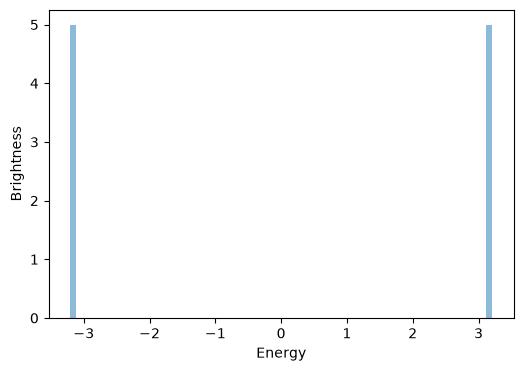

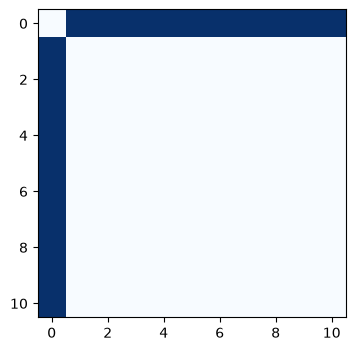

In [4]:
N = 10                                                # number of emitters

# dipole parameters
g = 1.0                                               # cavity coupling of a dipole d0 along e_c (energy unit)
field_c = np.array([1.0, 0, 0])                       # cavity field polarisation
dipoles = np.array([[1.0, 0, 0] for _ in range(N)])   # identical dipoles along e_c

# energy landscape
energies = np.zeros(N + 1)                                 # energies: cavity first, then emitters

# get the adjacency matrix of the star graph and the dipoles of the cavity and emitters
A, all_dipoles = star(dipoles, energies, g, field_c)

# energies and states from H
E0, C0 = np.linalg.eigh(A)

# get the energies, eigenstates, transition dipoles and brightness of the eigenstates
E, C, D, B = bright_states(A, all_dipoles)

# print the amount of bright states and of dark states
print(f'Number of bright states: {np.sum(B > 1e-8)}')
print(f'Number of dark states: {np.sum(B < 1e-8)}')

# plot the energies and brightness of the eigenstates
plt.figure(figsize=(6, 4))
plt.bar(E, B, width=0.1, color='C0', alpha=0.5)
plt.xlabel('Energy')
plt.ylabel('Brightness');

# plot the adjecency matrix of the star graph
plt.figure(figsize=(4, 4))
plt.imshow(A, cmap='Blues', interpolation='nearest');

In [39]:
k = -1
# C0[k]
C0[k]-C.T[k]

array([0.93071358, 0.14763211, 0.14763211, 0.14763211, 0.14763211,
       0.14763211, 0.14763211, 0.14763211, 0.14763211, 1.14763211,
       0.        ])

### Incoherent transitions

In the single excitation manifold we can have either population loss/gain or incoherent transfer between sites:

**Example:** Radiative emission (loss) at site $i$ at rate $k_{\rm rad}$
$$\dot{p}_i := -k_{\rm rad} p_i$$

**Example:** Excitation transfer/capture from site $i$ at rate $\Gamma$
$$\dot{p}_i := -\Gamma p_i$$

**General formulation.** Each channel $k$ has a rate $\Gamma_k$ and a normalised channel vector $w_k$ that says which states feed it. It removes population at the rate $j_k=\Gamma_k|w_k^\dagger\psi|^2$, and all channels together form the decay matrix
$$K=\sum_k\Gamma_k\,w_kw_k^\dagger, \qquad H_{\rm eff}=H-\tfrac{i}{2}K, \qquad i\dot\psi=H_{\rm eff}\psi .$$

- **Localised** transfer: every emitter has its own sink, $w_m=e_m$, so $K=\Gamma\sum_m e_me_m^\dagger$ and every state of the emitters decays.
- **Collective** transfer: one shared sink fed by the bright state $b$ (the emitter state the cavity couples to), so $K=\Gamma\,bb^\dagger$ and the states orthogonal to $b$ stay dark.

The yield of the sink is the probability that the excitation leaves through it, $\phi_s=\int_0^\infty\psi^\dagger K_s\psi\,dt$.

In [12]:
# radiative emission rate (loss) of the cavity only
k_rad = 0.1

# collective electron transfer rate (useful extraction) from the bright state of the emitters
Gamma = 0.2

# compose anti-Hermitian matrix K
K_rad = np.diag([k_rad*(k==0) for k in range(N+1)])

# bright state of the emitters (the one the cavity couples to) and collective sink
b = np.array([0*(k==0) + 1*(k>0) for k in range(N+1)]) / np.sqrt(N)
K_s = Gamma * np.outer(b, b)

# total anti-Hermitian matrix K = K_rad + K_s
K = K_rad + K_s

# effective non-Hermitian Hamiltonian H_eff = H - i/2 K
H_eff = A - 0.5j * K                                

### Yield

The system starts with one excitation in the cavity, $\psi_0=e_0$. We compute $\phi_s$ in three independent ways and compare them at the end.

**1. Time integral.** Propagate $\psi(t)=e^{-iH_{\rm eff}t}\psi_0$ and integrate the sink flux $\psi^\dagger K_s\psi$.

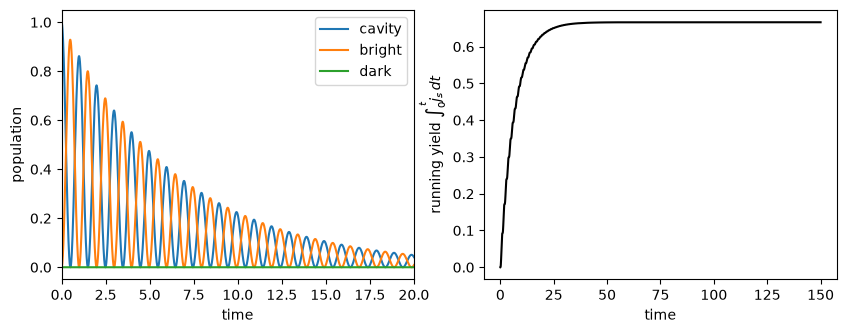

In [13]:
# initial state
psi0 = np.eye(N + 1)[0]                               # one excitation in the cavity

# propagate psi(t) with a fixed time step
t = np.linspace(0, 150, 15001)
U = expm(-1j * H_eff * (t[1] - t[0]))
psi = np.empty((len(t), N + 1), complex)
psi[0] = psi0
for n in range(1, len(t)):
    psi[n] = U @ psi[n - 1]

# sink flux and its time integral
j_s = np.einsum('ti,ij,tj->t', psi.conj(), K_s, psi).real
phi_time = np.trapezoid(j_s, t)

# populations of the cavity, of the bright state and of the dark states
p_c = np.abs(psi[:, 0]) ** 2
p_b = np.abs(psi @ b) ** 2
p_d = np.sum(np.abs(psi[:, 1:]) ** 2, axis=1) - p_b

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(t, p_c, label='cavity')
axs[0].plot(t, p_b, label='bright')
axs[0].plot(t, p_d, label='dark')
axs[0].set(xlabel='time', ylabel='population', xlim=(0, 20))
axs[0].legend()
axs[1].plot(t, np.cumsum(j_s) * (t[1] - t[0]), color='k')
axs[1].set(xlabel='time', ylabel=r'running yield $\int_0^t j_s\,dt$');

**2. Steady state.** The time-integrated state $M=\int_0^\infty\psi\psi^\dagger dt$ is the steady state under a constant injection of $\psi_0$. It solves $H_{\rm eff}M-MH_{\rm eff}^\dagger=-i\psi_0\psi_0^\dagger$, and $\phi_s={\rm Tr}(K_sM)$. The dark states never decay, so this equation is singular. Since $\psi_0$ has no dark component, the least-squares solution is the physical one.

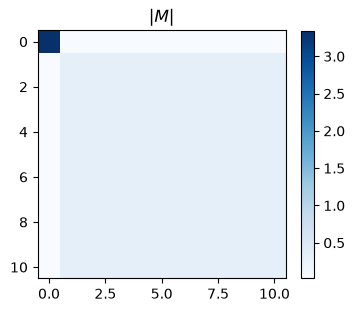

In [ ]:
# vectorised equation (columns of M stacked): (I x H_eff - H_eff^* x I) vec(M) = -i vec(psi0 psi0^dagger)
I = np.eye(N + 1)
L = np.kron(I, H_eff) - np.kron(H_eff.conj(), I)
M = np.linalg.lstsq(L, -1j * #np.outer(psi0, psi0).ravel(order='F'), rcond=None)[0].reshape(N + 1, N + 1, order='F')
 ## shouldnt it be outer (psi, psi_conj) instead?
phi_ss = np.trace(K_s @ M).real

plt.figure(figsize=(4, 4))
plt.imshow(np.abs(M), cmap='Blues', interpolation='nearest')
plt.colorbar(shrink=0.8)
plt.title(r'$|M|$');

**3. Spectral method.** Write $H_{\rm eff}=\sum_k\mu_k\,r_kl_k$ with right and left eigenvectors normalised so that $l_kr_k=1$. The initial state excites mode $k$ with amplitude $c_k=l_k\psi_0$, so $\psi(t)=\sum_kc_ke^{-i\mu_kt}r_k$, and the time integral gives
$$\phi_s=\sum_{k,l}\frac{c_k\,c_l^*\,(r_l^\dagger K_s r_k)}{i(\mu_k-\mu_l^*)} .$$
Only modes with $c_k\neq0$ contribute (the dark modes have $\mu_k=0$ and $c_k=0$).

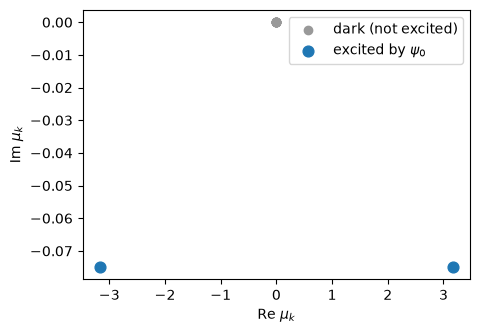

In [15]:
# eigenvalues and left/right eigenvectors of H_eff, normalised so that l_k r_k = 1
mu, l, r = eig(H_eff, left=True)
l = l.conj() / np.sum(l.conj() * r, 0)

# amplitudes c_k = l_k psi0, keep only the excited modes
c = l.T @ psi0
on = np.abs(c) > 1e-10
mu_on, c_on, r_on = mu[on], c[on], r[:, on]

# double sum over the excited modes
Kr = r_on.conj().T @ K_s @ r_on                        # Kr[l, k] = r_l^dagger K_s r_k
phi_spec = np.sum(np.outer(c_on, c_on.conj()) * Kr.T / (1j * (mu_on[:, None] - mu_on.conj()[None, :]))).real

plt.figure(figsize=(5, 3.5))
plt.scatter(mu.real[~on], mu.imag[~on], color='0.6', label='dark (not excited)')
plt.scatter(mu.real[on], mu.imag[on], s=60, color='C0', label=r'excited by $\psi_0$')
plt.xlabel(r'Re $\mu_k$')
plt.ylabel(r'Im $\mu_k$')
plt.legend();

### Check and comparison

The cavity talks only to the bright state, with collective coupling $G=\sqrt N g$, so the problem reduces to two levels. For two resonant levels the yield is $\phi_s=4G^2\Gamma/\big((k_{\rm rad}+\Gamma)(4G^2+k_{\rm rad}\Gamma)\big)$. The excitation leaves through either the sink or the cavity, so $\phi_s+\phi_{\rm rad}=1$ with $\phi_{\rm rad}={\rm Tr}(K_{\rm rad}M)$.

phi_s + phi_rad = 1.000000
max dark population = 2.2e-16
 time integral: phi_s = 0.666333   error = -1.4e-10
  steady state: phi_s = 0.666333   error = -1.4e-15
      spectral: phi_s = 0.666333   error = +5.6e-16


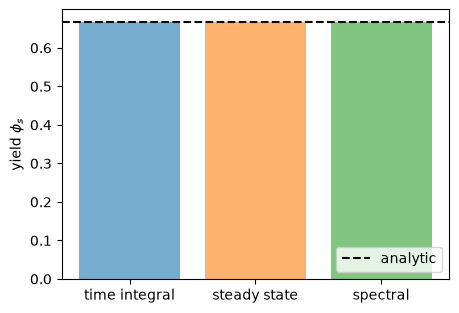

In [16]:
# analytic two-level result
G = np.linalg.norm(A[0, 1:])
phi_exact = 4 * G ** 2 * Gamma / ((k_rad + Gamma) * (4 * G ** 2 + k_rad * Gamma))

# yield into the radiative channel and conservation of probability
phi_rad = np.trace(K_rad @ M).real
print(f'phi_s + phi_rad = {phi_ss + phi_rad:.6f}')
print(f'max dark population = {p_d.max():.1e}')

# compare the three methods with the analytic result
methods = {'time integral': phi_time, 'steady state': phi_ss, 'spectral': phi_spec}
for name, phi in methods.items():
    print(f'{name:>14}: phi_s = {phi:.6f}   error = {phi - phi_exact:+.1e}')

plt.figure(figsize=(5, 3.5))
plt.bar(methods.keys(), methods.values(), color=['C0', 'C1', 'C2'], alpha=0.6)
plt.axhline(phi_exact, color='k', ls='--', label='analytic')
plt.ylabel(r'yield $\phi_s$')
plt.legend(loc='lower right');